# Step 1 — Understand the vibration data

The aim is to see what a compressor can use, before any model is trained.

One recording is 1.28 s from one sensor on the output-shaft bearing: the time, the shaft speed, then 16,384 snapshots of the push in g.

The release is six turbines, about 4.8 GiB, same machine and same sensor. What changes the vibration is the speed, and the rows are stored in time order, so the start of a file is only one speed. This notebook keeps every complete row in five 2 MB slices of `DATASET02.csv`: the start, one quarter, halfway, three quarters, and the end.

Martin del Campo Barraza, Sandin, and Strömbergsson, Luleå University of Technology, 2018. DOI [10.5878/bcmv-wq08](https://doi.org/10.5878/bcmv-wq08).


In [1]:
import os
import sys
from pathlib import Path

import numpy as np

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
from signals import FS, energy_bins, load_subset, main_peak, row_stats, shake_parts, spectrum

years, rpm, samples, text_bytes, file_size = load_subset()
n_seg, n_samples = samples.shape
print(f"DATASET02.csv is {file_size:,} bytes")
print(f"subset: {n_seg} segments x {n_samples} samples")
print(f"years {years.min():.3f} to {years.max():.3f}")
print(f"speed {rpm.min():.1f} to {rpm.max():.1f} RPM")


loaded data/dataset02.npz (27 segments)
DATASET02.csv is 893,424,837 bytes
subset: 27 segments x 16384 samples
years 0.000 to 3.844
speed 705.4 to 1160.5 RPM


## Each recording

These numbers are here to see what changes with speed, and whether the next snapshot is easy to guess. Sorted by speed. **rms** is the usual push, **peak** is the hardest snapshot. **kurt** near 3 means a steady wiggle. **lag1** is how much one snapshot looks like the next. **dstd** is the size of the jump compared with the snapshot. It stays near 0.6, so storing the jump saves only a little.


In [2]:
stats = [row_stats(x) for x in samples]
order = np.argsort(rpm)

header = f"{'i':>3} {'years':>8} {'rpm':>8} {'rms_g':>8} {'peak_g':>8} {'kurt':>7} {'lag1':>7} {'dstd':>7}"
print(header)
print("-" * len(header))
for i in order:
    row = stats[i]
    print(
        f"{i:3d} {years[i]:8.3f} {rpm[i]:8.1f} {row['rms']:8.3f} "
        f"{row['peak']:8.3f} {row['kurt']:7.1f} {row['lag1']:7.3f} {row['dstd']:7.3f}"
    )

print()
print(f"Published rate {FS} Hz x {n_samples} samples = {n_samples / FS:.2f} s per segment.")
print(f"CSV text is {text_bytes.mean() / 1e3:.0f} KB per row on average.")
print(f"The same samples as float32 are {n_samples * 4 / 1e3:.1f} KB, and as float64 {n_samples * 8 / 1e3:.1f} KB.")
err_f32 = np.max(np.abs(samples - samples.astype(np.float32)))
print(f"Largest change if these values are stored as float32: {err_f32:.3e} g.")


  i    years      rpm    rms_g   peak_g    kurt    lag1    dstd
---------------------------------------------------------------
  6    0.709    705.4    0.211    0.806     3.0   0.824   0.594
  1    0.001    709.4    0.203    0.943     3.2   0.749   0.708
  2    0.002    713.1    0.432    1.264     2.2   0.922   0.394
 15    1.667    743.5    0.218    1.055     3.5   0.816   0.606
  0    0.000    750.9    0.322    1.305     2.9   0.721   0.747
 26    3.844    794.0    0.560    1.956     2.7   0.860   0.529
 24    3.841    803.4    0.492    1.855     2.8   0.846   0.555
 20    2.754    818.5    0.606    2.744     2.9   0.837   0.571
 16    2.749    819.8    0.565    2.334     2.9   0.833   0.577
 11    1.662    844.5    0.716    3.038     3.1   0.811   0.614
 18    2.751    861.1    0.865    3.250     2.9   0.829   0.585
  5    0.005    878.0    0.257    1.186     3.3   0.637   0.852
 22    3.837    880.6    0.758    3.157     3.0   0.849   0.550
  9    0.712    883.7    0.672    2.746 

## How one snapshot is formed

The accelerometer stores one combined acceleration value at each instant. The plot separates three strong shakes in the first recording only to show how this works. At the marked instant they are **+0.17 g**, **+0.11 g**, and **−0.04 g**. Together they make **+0.24 g**, almost the same as the stored snapshot.

The stored snapshot contains every shake and noise, not only these three. At another instant some shakes add and others cancel.

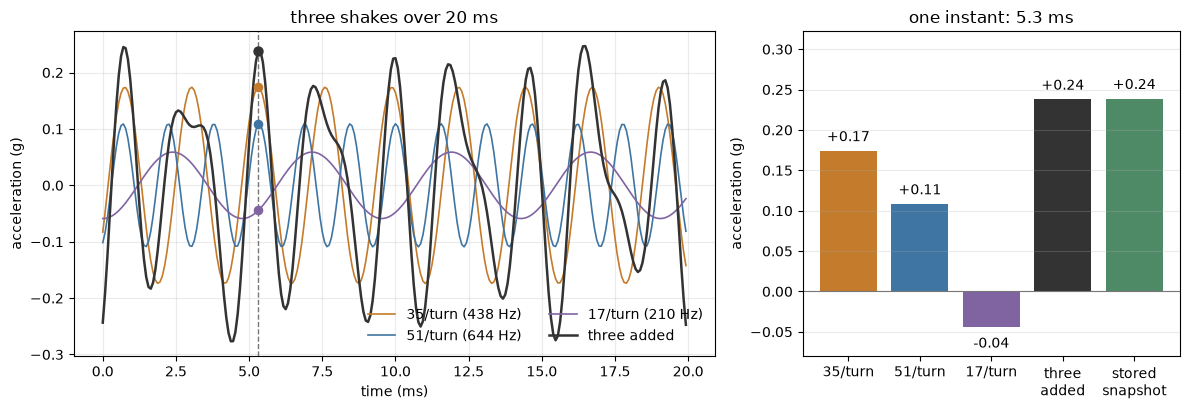

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt

first = samples[0]
part_hz, parts = shake_parts(first, FS)
show_n = int(0.02 * FS)
t_ms = np.arange(show_n) / FS * 1e3
added = parts.sum(axis=0)

# Pick a clear instant where the 35-per-turn shake is at the top of its swing.
start = int(0.005 * FS)
stop = int(0.018 * FS)
mark = start + np.argmax(parts[0, start:stop])
mark_ms = mark / FS * 1e3
shaft_hz = rpm[0] / 60.0
part_order = part_hz / shaft_hz

colors = ["#c47b2b", "#3f75a2", "#8064a2"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})

for j in range(3):
    axes[0].plot(
        t_ms,
        parts[j, :show_n],
        color=colors[j],
        lw=1.2,
        label=f"{part_order[j]:.0f}/turn ({part_hz[j]:.0f} Hz)",
    )
axes[0].plot(t_ms, added[:show_n], color="#333333", lw=1.8, label="three added")
axes[0].axvline(mark_ms, color="#777777", ls="--", lw=1)
for j in range(3):
    axes[0].scatter(mark_ms, parts[j, mark], color=colors[j], s=35, zorder=3)
axes[0].scatter(mark_ms, added[mark], color="#333333", s=42, zorder=3)
axes[0].set_xlabel("time (ms)")
axes[0].set_ylabel("acceleration (g)")
axes[0].set_title("three shakes over 20 ms")
axes[0].legend(frameon=False, ncol=2)
axes[0].grid(alpha=0.25)

at_mark = parts[:, mark]
values = np.r_[at_mark, added[mark], first[mark]]
labels = [
    f"{part_order[0]:.0f}/turn",
    f"{part_order[1]:.0f}/turn",
    f"{part_order[2]:.0f}/turn",
    "three\nadded",
    "stored\nsnapshot",
]
bar_colors = colors + ["#333333", "#4f8a67"]
bars = axes[1].bar(labels, values, color=bar_colors)
axes[1].axhline(0, color="#777777", lw=0.8)
axes[1].set_ylabel("acceleration (g)")
axes[1].set_title(f"one instant: {mark_ms:.1f} ms")
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_ylim(min(values.min() * 1.5, -0.08), values.max() * 1.35)
for bar, value in zip(bars, values):
    y = value + (0.008 if value >= 0 else -0.012)
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        y,
        f"{value:+.2f}",
        ha="center",
        va="bottom" if value >= 0 else "top",
    )

fig.tight_layout()
plt.show()

## Waveform

A single number can hide the shape, so three recordings are drawn: slowest, middle speed, and fastest. Left is the whole 1.28 s: the band stays steady inside one recording and gets taller as the shaft spins faster. Right is the first 20 ms, so the back-and-forth is visible.


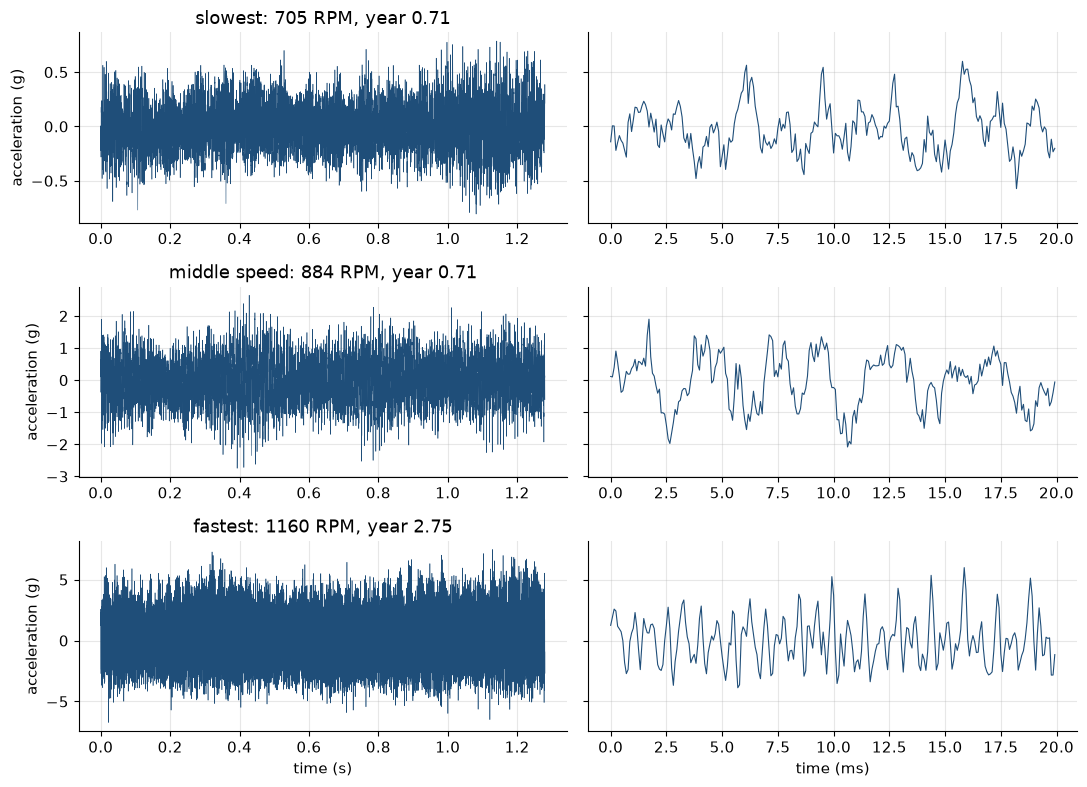

In [4]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

mid = order[len(order) // 2]
picked = [order[0], mid, order[-1]]
labels = ["slowest", "middle speed", "fastest"]
zoom_n = int(0.02 * FS)
t_full = np.arange(n_samples) / FS
t_zoom = t_full[:zoom_n]

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharey="row")
for row, (i, label) in enumerate(zip(picked, labels)):
    axes[row, 0].plot(t_full, samples[i], color="#1f4e79", lw=0.4)
    axes[row, 1].plot(t_zoom * 1e3, samples[i, :zoom_n], color="#1f4e79", lw=0.8)
    axes[row, 0].set_ylabel("acceleration (g)")
    axes[row, 0].set_title(f"{label}: {rpm[i]:.0f} RPM, year {years[i]:.2f}")
axes[2, 0].set_xlabel("time (s)")
axes[2, 1].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()


## Loudest shake

The raw snapshots mix every shake together, so each recording is split into shake speeds. Left is shakes per second. Right is shakes per shaft turn. The orange line is the strongest shake. It moves in hertz when the shaft speeds up, and stays at 35 shakes per turn. These three rows are that common case. The speed is already stored once per recording, so a compressor can be told where this shake will be.


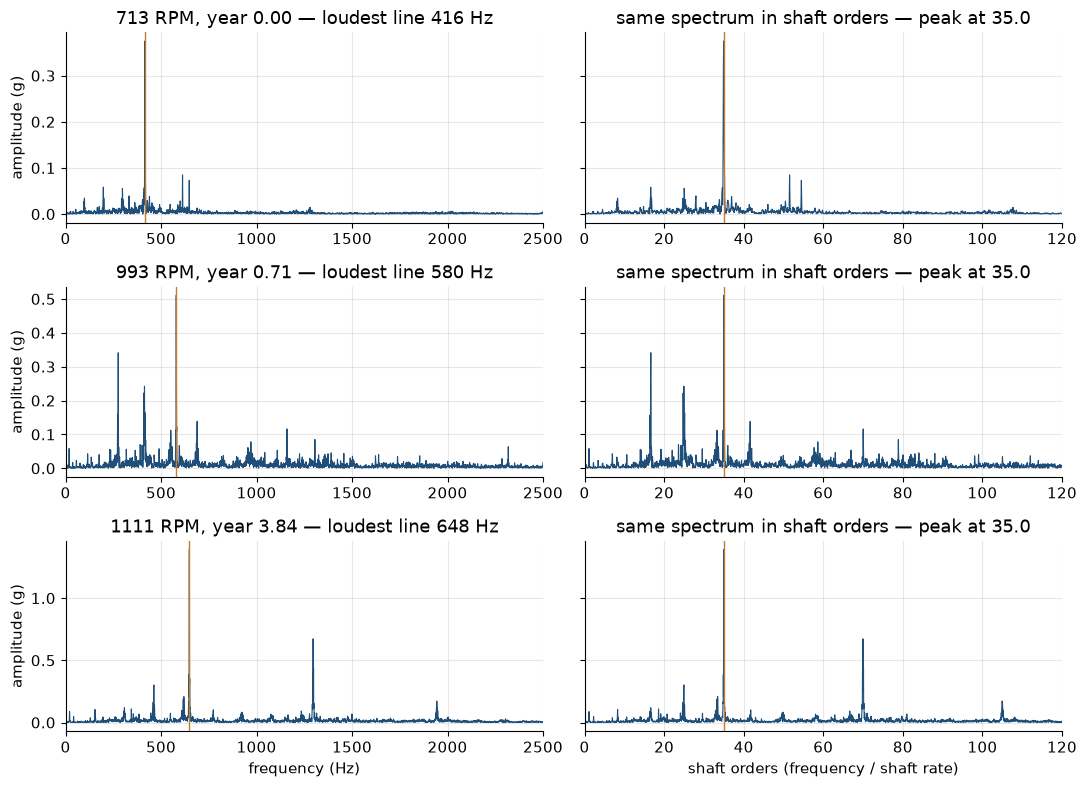

In [5]:
FMAX = 2500
OMAX = 120
orders = np.array([main_peak(samples[i], rpm[i])[1] for i in range(n_seg)])
at_35 = np.flatnonzero(np.abs(orders - 35) < 0.5)
at_35 = at_35[np.argsort(rpm[at_35])]
show = [at_35[0], at_35[len(at_35) // 2], at_35[-1]]

fig, axes = plt.subplots(3, 2, figsize=(11, 8), sharey="row")
for row, i in enumerate(show):
    freq, amp = spectrum(samples[i], FS)
    hz, odr = main_peak(samples[i], rpm[i])
    keep = freq <= FMAX
    axes[row, 0].plot(freq[keep], amp[keep], color="#1f4e79", lw=0.8)
    axes[row, 0].axvline(hz, color="#c47b2b", lw=1.0)
    axes[row, 0].set_xlim(0, FMAX)
    axes[row, 0].set_ylabel("amplitude (g)")
    axes[row, 0].set_title(f"{rpm[i]:.0f} RPM, year {years[i]:.2f} — loudest line {hz:.0f} Hz")

    shaft_orders = freq / (rpm[i] / 60.0)
    keep = shaft_orders <= OMAX
    axes[row, 1].plot(shaft_orders[keep], amp[keep], color="#1f4e79", lw=0.8)
    axes[row, 1].axvline(odr, color="#c47b2b", lw=1.0)
    axes[row, 1].set_xlim(0, OMAX)
    axes[row, 1].set_title(f"same spectrum in shaft orders — peak at {odr:.1f}")

axes[2, 0].set_xlabel("frequency (Hz)")
axes[2, 1].set_xlabel("shaft orders (frequency / shaft rate)")
fig.tight_layout()
plt.show()


## All 27 recordings

The three plots above could be special cases, so the same checks are made on every recording. A faster shaft shakes harder. The loudest shake stays on the same count per turn, mostly 35. Half the strength sits in about 11 shake speeds. Reaching 90% takes about 1,000 of 8,192, so a few strong shakes are not the whole recording.

The histograms ask whether storing the jump, instead of the snapshot, is enough. They are one middle-speed recording. The right hill is narrower than the snapshots, and still wide enough that the saving is modest.


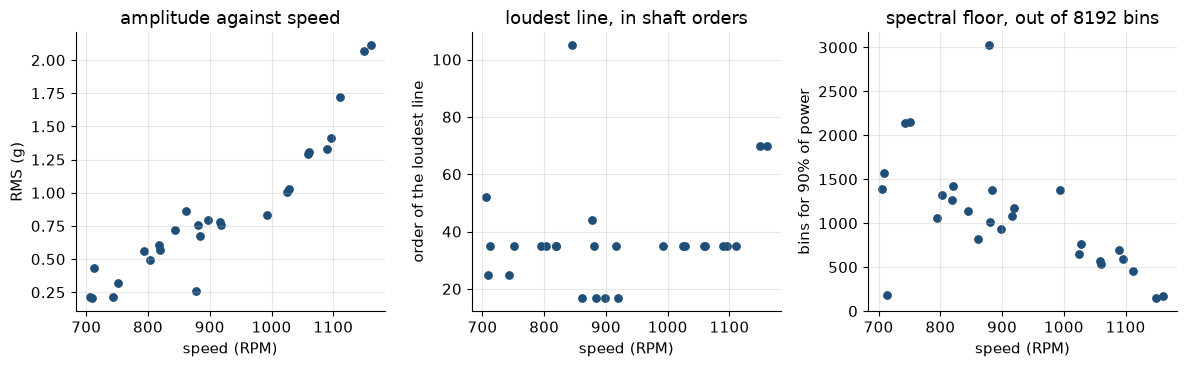

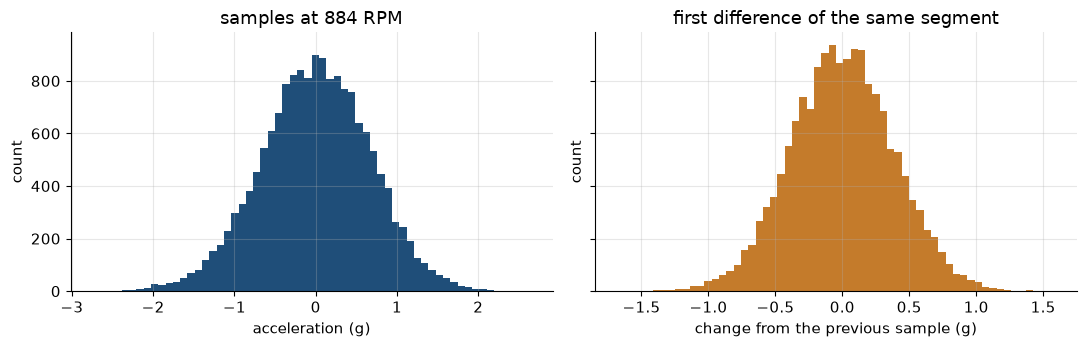

Segments: 27
Years: 0.00 to 3.84
Speed: 705 to 1160 RPM
RMS: 0.203 to 2.113 g (median 0.760)
Median peak 3.039 g
Median lag-1 correlation 0.835
Median std(difference) / std(sample) 0.574
Loudest line within 0.5 of order 35: 59% of segments
Median bins for 50% of the power: 11 of 8192
Median bins for 90% of the power: 1057 of 8192
Median kurtosis 2.9 (Gaussian would be 3)


In [6]:
n50 = np.array([energy_bins(x, 0.50) for x in samples])
n90 = np.array([energy_bins(x, 0.90) for x in samples])
peak_ord = np.array([main_peak(x, speed)[1] for x, speed in zip(samples, rpm)])
rms = np.array([row["rms"] for row in stats])
dstd = np.array([row["dstd"] for row in stats])
lag1 = np.array([row["lag1"] for row in stats])
kurt = np.array([row["kurt"] for row in stats])
n_bins = n_samples // 2
frac_35 = np.mean(np.abs(peak_ord - 35) < 0.5)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].scatter(rpm, rms, c="#1f4e79", s=28)
axes[0].set_xlabel("speed (RPM)")
axes[0].set_ylabel("RMS (g)")
axes[0].set_title("amplitude against speed")

axes[1].scatter(rpm, peak_ord, c="#1f4e79", s=28)
axes[1].set_xlabel("speed (RPM)")
axes[1].set_ylabel("order of the loudest line")
axes[1].set_title("loudest line, in shaft orders")

axes[2].scatter(rpm, n90, c="#1f4e79", s=28)
axes[2].set_xlabel("speed (RPM)")
axes[2].set_ylabel("bins for 90% of power")
axes[2].set_title(f"spectral floor, out of {n_bins} bins")
fig.tight_layout()
plt.show()

example = samples[mid]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
axes[0].hist(example, bins=60, color="#1f4e79")
axes[0].set_title(f"samples at {rpm[mid]:.0f} RPM")
axes[0].set_xlabel("acceleration (g)")
axes[1].hist(np.diff(example), bins=60, color="#c47b2b")
axes[1].set_title("first difference of the same segment")
axes[1].set_xlabel("change from the previous sample (g)")
for ax in axes:
    ax.set_ylabel("count")
fig.tight_layout()
plt.show()

print(f"Segments: {n_seg}")
print(f"Years: {years.min():.2f} to {years.max():.2f}")
print(f"Speed: {rpm.min():.0f} to {rpm.max():.0f} RPM")
print(f"RMS: {rms.min():.3f} to {rms.max():.3f} g (median {np.median(rms):.3f})")
print(f"Median peak {np.median([row['peak'] for row in stats]):.3f} g")
print(f"Median lag-1 correlation {np.median(lag1):.3f}")
print(f"Median std(difference) / std(sample) {np.median(dstd):.3f}")
print(f"Loudest line within 0.5 of order 35: {100 * frac_35:.0f}% of segments")
print(f"Median bins for 50% of the power: {np.median(n50):.0f} of {n_bins}")
print(f"Median bins for 90% of the power: {np.median(n90):.0f} of {n_bins}")
print(f"Median kurtosis {np.median(kurt):.1f} (Gaussian would be 3)")


## Eight recordings at one shaft speed

The eight recordings closest to 1,106 rpm. Their speeds sit between 1,105.8 and 1,106.1. Each entry is the correlation of one whole 1.28 s waveform with another.

   row    years      rpm
   336    0.295  1105.91
   921    0.884  1106.13
  1278    1.365  1105.96
  1635    1.859  1106.01
  1874    2.205  1105.93
  2093    2.538  1105.95
  2188    2.672  1105.85
  2572    3.244  1105.95


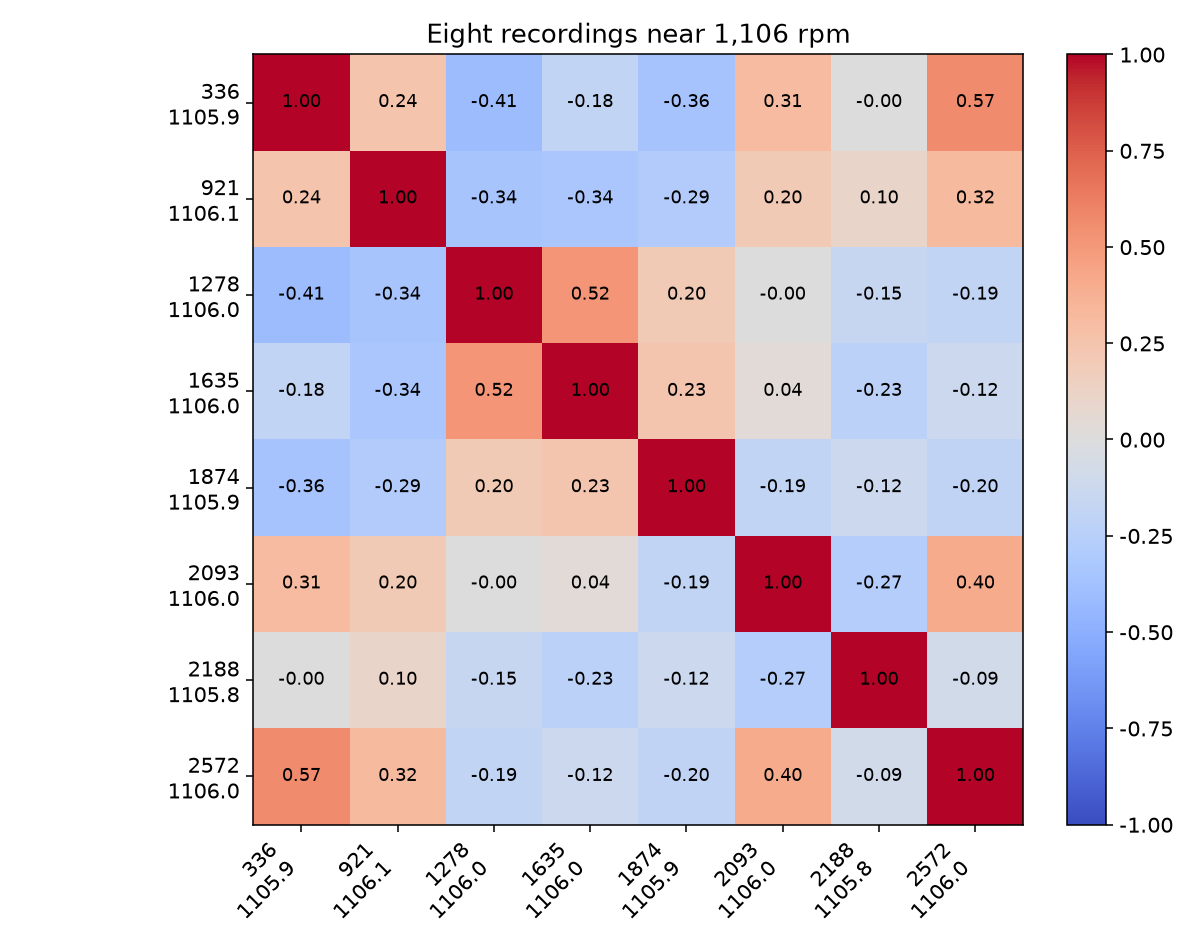

In [1]:
stored = np.load("data/dataset02_f32.npz")
years_all = stored["years"]
rpm_all = stored["rpm"]
signal_all = stored["signal"]

target = 1106.0
picked = np.sort(np.argsort(np.abs(rpm_all - target))[:8])
corr = np.corrcoef(signal_all[picked])

print(f"{'row':>6} {'years':>8} {'rpm':>8}")
for row in picked:
    print(f"{row:6d} {years_all[row]:8.3f} {rpm_all[row]:8.2f}")

labels = [f"{row}\n{rpm_all[row]:.1f}" for row in picked]
fig, ax = plt.subplots(figsize=(8.6, 6.8))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(8), labels, rotation=45, ha="right")
ax.set_yticks(range(8), labels)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{corr[i, j]:.2f}", ha="center", va="center", color="black", fontsize=9)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
ax.set_title("Eight recordings near 1,106 rpm")
fig.tight_layout()
plt.show()
